# Sampling, the Central Limit Theorem and the bootstrap 

1. Population and setup
2. Sampling distribution of the mean and the CLT (ADR, LeadTime, cancellation)
3. Standard error shrinks with √n
4. Confidence-interval coverage
5. Bootstrap
6. Sampling vs bootstrap vs permutation

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.color": "#e6e6e3",
                     "axes.edgecolor": "#b5b4ad", "axes.titlecolor": INK, "axes.labelcolor": MUTED})

df = pd.read_csv("../data/processed/hotel_bookings_cleaned.csv")
FIG_DIR = "../outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(df.shape)

(87396, 37)


**Population.** We treat the 87,396 cleaned bookings as the *population*, so we know the true values and can check what samples do.
For ADR we leave out the single ADR = 5,400 booking, so one extreme value doesn't dominate (87,395 bookings).

In [2]:
population = {
    "ADR": df.loc[df["ADR"] < 1000, "ADR"].to_numpy(),
    "LeadTime": df["LeadTime"].to_numpy(),
    "Cancelled (0/1)": df["IsCanceled"].to_numpy(),
}

pop_table = pd.DataFrame({name: {"N": len(v), "mean (μ)": v.mean(), "SD (σ)": v.std(), "skewness": stats.skew(v)}
                          for name, v in population.items()}).T
print(pop_table.round(3))

                       N  mean (μ)  SD (σ)  skewness
ADR              87395.0   106.278  52.017     0.863
LeadTime         87396.0    79.891  86.052     1.432
Cancelled (0/1)  87396.0     0.275   0.446     1.008


## 2. The sampling distribution and the CLT

**Idea:** take a random sample of n bookings, work out its mean, and repeat 5,000 times. The 5,000 means form the *sampling distribution*.
The CLT says that, for large enough n, this distribution is close to a normal curve centred on μ with standard deviation σ/√n (the *standard error*), whatever the shape of the population.

Samples are drawn with replacement. With n ≤ 500 out of about 87,000 bookings, this makes no practical difference.

In [3]:
SIZES = [30, 100, 500]
REPS = 5000

def sample_means(values, n, reps=REPS):
    idx = rng.integers(0, len(values), size=(reps, n))
    return values[idx].mean(axis=1)

def clt_experiment(name, sizes=SIZES):
    v = population[name]
    mu, sigma = v.mean(), v.std()
    means = {n: sample_means(v, n) for n in sizes}
    table = pd.DataFrame({
        "n": sizes,
        "mean of sample means": [means[n].mean() for n in sizes],
        "empirical SD of means": [means[n].std() for n in sizes],
        "theoretical σ/√n": [sigma / np.sqrt(n) for n in sizes],
        "skewness of means": [stats.skew(means[n]) for n in sizes],
    })
    table["SD ratio"] = table["empirical SD of means"] / table["theoretical σ/√n"]
    return mu, sigma, means, table

def plot_clt(name, mu, sigma, means, unit, file):
    lo = min(m.min() for m in means.values())
    hi = max(m.max() for m in means.values())
    x = np.linspace(lo, hi, 400)
    fig, axes = plt.subplots(1, len(means), figsize=(14, 4), sharex=True)
    for ax, (n, m) in zip(axes, means.items()):
        v = population[name]
        # a 0/1 variable gives only n + 1 possible sample means, so put one bin on each
        if set(np.unique(v)) <= {0, 1}:
            k = np.round(m * n)
            bins = (np.arange(k.min(), k.max() + 2) - 0.5) / n
        else:
            bins = 50
        ax.hist(m, bins=bins, density=True, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5 if n <= 100 else 0)
        ax.plot(x, stats.norm.pdf(x, mu, sigma / np.sqrt(n)), color=ORANGE, lw=2, label="normal curve N(μ, σ/√n)")
        ax.axvline(mu, color=INK, lw=1, ls="--")
        ax.set_title(f"n = {n}")
        ax.set_xlabel(f"Sample mean {name} {unit}".strip())
    axes[0].set_ylabel("Density")
    axes[0].legend(loc="upper left", fontsize=8)
    fig.suptitle(f"Sample means of {name} get narrower and more bell-shaped as n grows", color=INK)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{file}", dpi=120, bbox_inches="tight")
    plt.show()

### 2a. ADR

Population ADR: μ = 106.28, σ = 52.02
  n  mean of sample means  empirical SD of means  theoretical σ/√n  skewness of means  SD ratio
 30               106.151                  9.560             9.497              0.192     1.007
100               106.276                  5.214             5.202              0.097     1.002
500               106.239                  2.299             2.326             -0.002     0.988


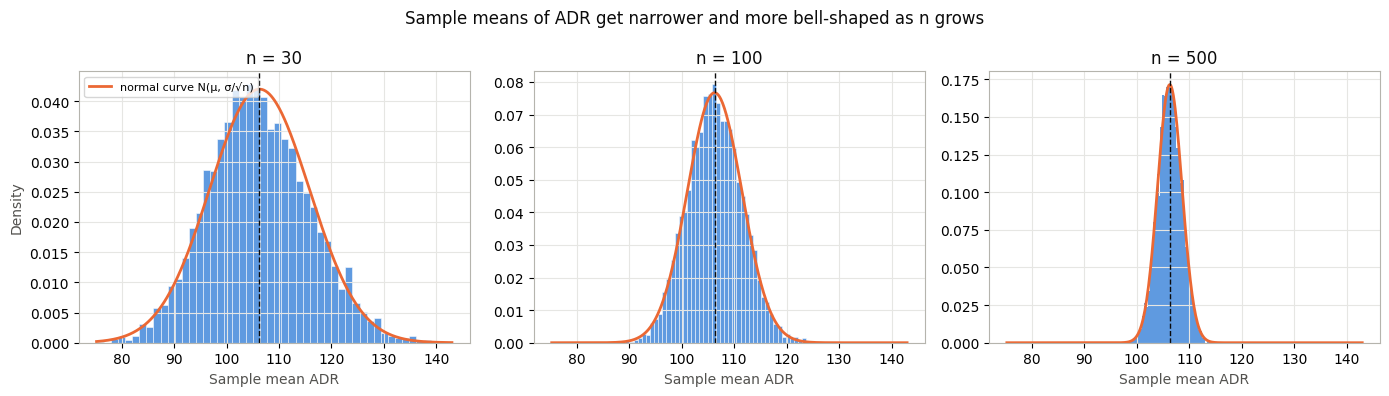

In [4]:
mu, sigma, means_adr, table_adr = clt_experiment("ADR")
print(f"Population ADR: μ = {mu:.2f}, σ = {sigma:.2f}")
print(table_adr.round(3).to_string(index=False))
plot_clt("ADR", mu, sigma, means_adr, "", "06_clt_adr.png")

**Result:** the means centre on the true μ = 106.28, and their spread matches the theory σ/√n almost exactly (ratio 0.99 to 1.01). The curve gets narrower as n grows, and the skewness of the means falls from 0.19 to 0.00. ADR without the 5,400 value is only mildly skewed (0.86), so even n = 30 already looks close to normal.

### 2b. LeadTime (more skewed)

Population LeadTime: μ = 79.89, σ = 86.05
  n  mean of sample means  empirical SD of means  theoretical σ/√n  skewness of means  SD ratio
 30                79.730                 15.767            15.711              0.224     1.004
100                79.862                  8.575             8.605              0.166     0.996
500                79.836                  3.839             3.848              0.064     0.998


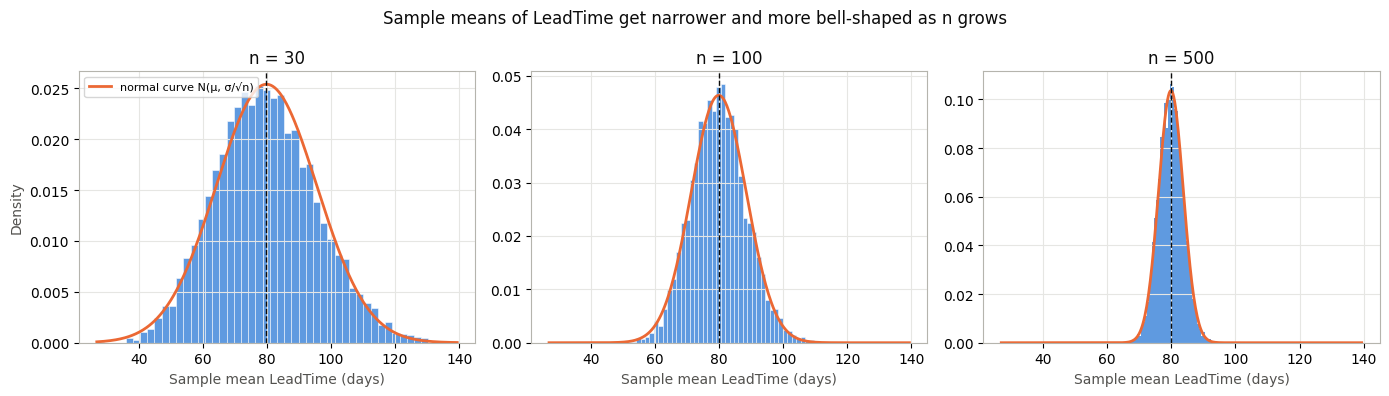

In [5]:
mu_lt, sigma_lt, means_lt, table_lt = clt_experiment("LeadTime")
print(f"Population LeadTime: μ = {mu_lt:.2f}, σ = {sigma_lt:.2f}")
print(table_lt.round(3).to_string(index=False))
plot_clt("LeadTime", mu_lt, sigma_lt, means_lt, "(days)", "06_clt_leadtime.png")

### 2c. Cancellation (a 0/1 variable, so the sample mean is a sample proportion)

Population cancellation rate p = 0.2749; σ = √(p(1−p)) = 0.4465
  n  mean of sample means  empirical SD of means  theoretical σ/√n  skewness of means  SD ratio
 30                0.2742                 0.0814            0.0815             0.1722    0.9987
100                0.2751                 0.0450            0.0446             0.0820    1.0072
500                0.2749                 0.0198            0.0200             0.0417    0.9941


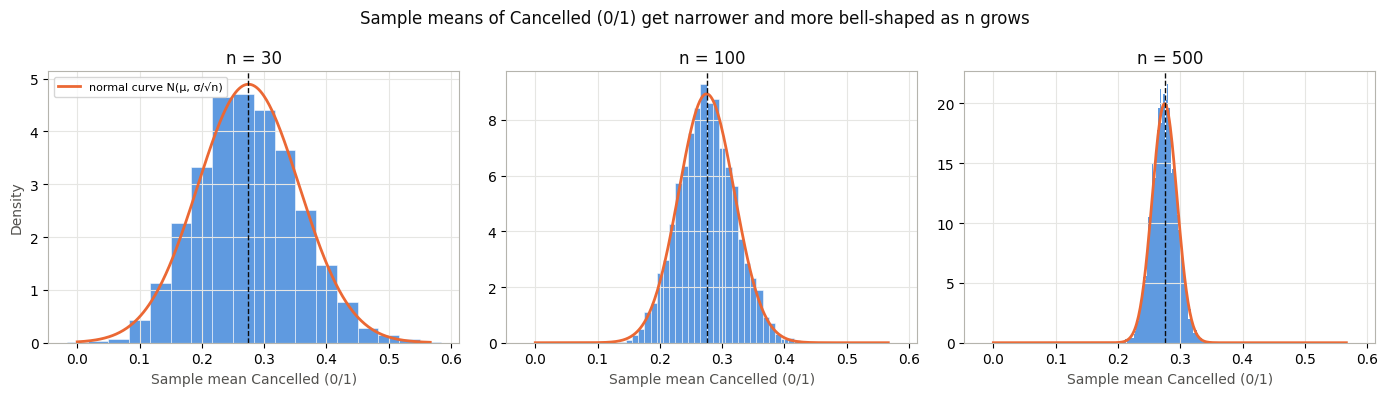

In [6]:
mu_c, sigma_c, means_c, table_c = clt_experiment("Cancelled (0/1)")
print(f"Population cancellation rate p = {mu_c:.4f}; σ = √(p(1−p)) = {sigma_c:.4f}")
print(table_c.round(4).to_string(index=False))
plot_clt("Cancelled (0/1)", mu_c, sigma_c, means_c, "", "06_clt_proportion.png")

**Result:** LeadTime is more skewed (1.43), but its sample means are still close to normal, and the skewness of the means falls from 0.22 to 0.06.
For cancellation, each booking is only 0 or 1, so the sample mean is the *share* that cancelled. With n = 30 there are only 31 possible values, so the n = 30 histogram is made of separate bars. Its spread still matches the theory √(p(1−p)/n) = 0.0815, and by n = 500 it is a smooth bell curve.

### 2d. Does the shape really become normal? Q-Q plots for LeadTime

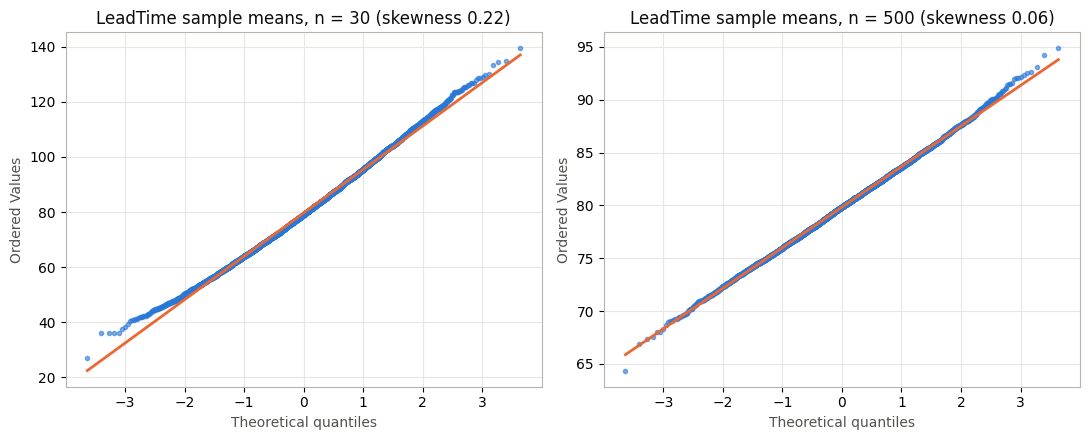

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, n in zip(axes, [30, 500]):
    stats.probplot(means_lt[n], dist="norm", plot=ax)
    ax.get_lines()[0].set(color=BLUE, markersize=3, alpha=0.6)
    ax.get_lines()[1].set(color=ORANGE, lw=2)
    ax.set_title(f"LeadTime sample means, n = {n} (skewness {stats.skew(means_lt[n]):.2f})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_clt_qq_leadtime.png", dpi=120, bbox_inches="tight")
plt.show()

**Result:** if the means were exactly normal, the dots would sit on the line. At n = 30 the lowest dots bend away (left over from LeadTime's long tail); at n = 500 they follow the line. The CLT is about **large** n, and how large depends on how skewed the data is.

## 3. Standard error shrinks with √n

If SE = σ/√n, then on a log-log plot SE against n is a straight line with slope −1/2. Quadrupling n halves the SE.

Fitted slope on the log-log scale: -0.500 (theory: -0.5)


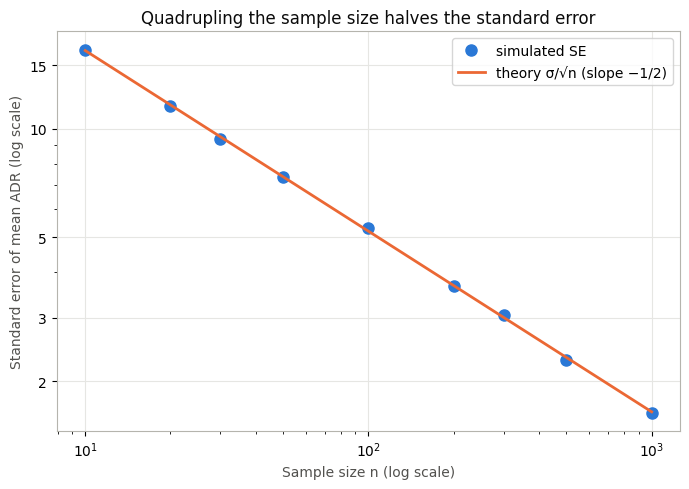

In [8]:
ns = np.array([10, 20, 30, 50, 100, 200, 300, 500, 1000])
emp_se = np.array([sample_means(population["ADR"], n, reps=2000).std() for n in ns])
slope = np.polyfit(np.log(ns), np.log(emp_se), 1)[0]
print(f"Fitted slope on the log-log scale: {slope:.3f} (theory: -0.5)")

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(ns, emp_se, "o", color=BLUE, markersize=8, label="simulated SE")
ax.loglog(ns, sigma / np.sqrt(ns), color=ORANGE, lw=2, label="theory σ/√n (slope −1/2)")
ax.set_xlabel("Sample size n (log scale)")
ax.set_ylabel("Standard error of mean ADR (log scale)")
ax.set_yticks([2, 3, 5, 10, 15])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_yaxis().set_minor_formatter(plt.NullFormatter())
ax.set_title("Quadrupling the sample size halves the standard error")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_standard_error_vs_n.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. What does "95% confidence" mean? A coverage simulation

Draw 1,000 samples of n = 100 ADR values. From each, build a 95% interval: mean ± t* · s/√n. Count how many intervals contain the true μ.

t* = 1.984
947 of 1000 intervals contain the true mean μ = 106.28  ->  coverage 94.7%


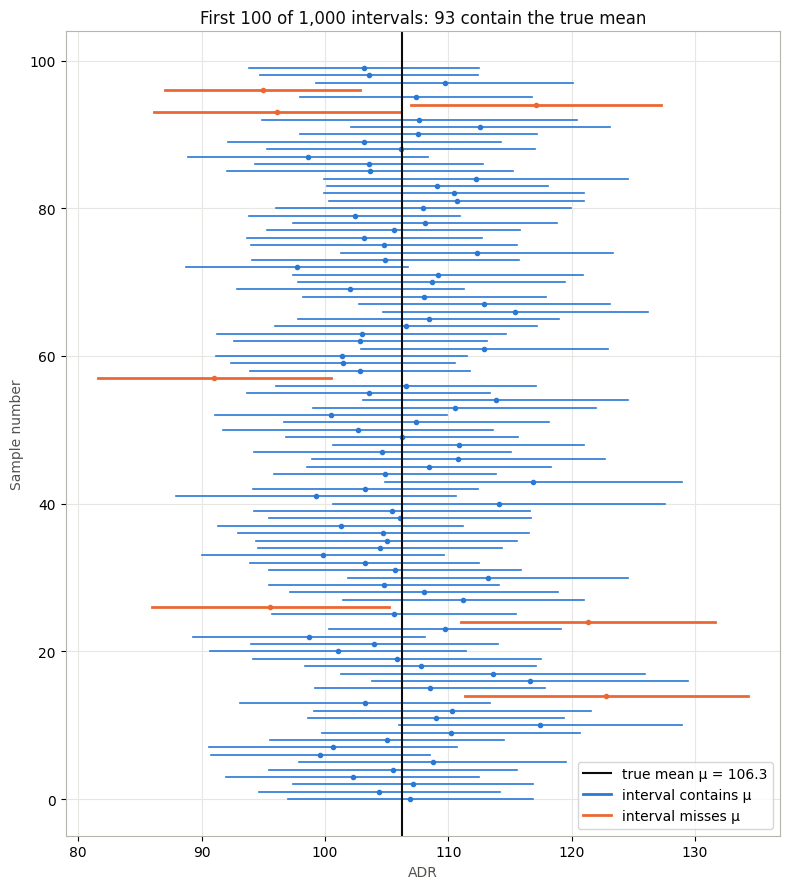

In [9]:
n, reps = 100, 1000
t_star = stats.t.ppf(0.975, df=n - 1)
idx = rng.integers(0, len(population["ADR"]), size=(reps, n))
samples = population["ADR"][idx]
m = samples.mean(axis=1)
half = t_star * samples.std(axis=1, ddof=1) / np.sqrt(n)
lower, upper = m - half, m + half
hit = (lower <= mu) & (mu <= upper)
print(f"t* = {t_star:.3f}")
print(f"{hit.sum()} of {reps} intervals contain the true mean μ = {mu:.2f}  ->  coverage {hit.mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 9))
for i in range(100):
    color = BLUE if hit[i] else ORANGE
    ax.plot([lower[i], upper[i]], [i, i], color=color, lw=2 if not hit[i] else 1.2)
    ax.plot(m[i], i, "o", color=color, markersize=3)
ax.axvline(mu, color=INK, lw=1.5, label=f"true mean μ = {mu:.1f}")
ax.plot([], [], color=BLUE, lw=2, label="interval contains μ")
ax.plot([], [], color=ORANGE, lw=2, label="interval misses μ")
ax.set_xlabel("ADR")
ax.set_ylabel("Sample number")
ax.set_title(f"First 100 of 1,000 intervals: {hit[:100].sum()} contain the true mean")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_ci_coverage.png", dpi=120, bbox_inches="tight")
plt.show()

**Result:** 947 of 1,000 intervals (94.7%) contain the true mean, very close to 95%. In the first 100 shown, 93 do.
So "95% confident" describes the **method**: about 95 out of 100 intervals built this way catch the true value. Any single interval either contains μ or it doesn't.

## 5. The bootstrap

In real life we have **one** sample, not the whole population. The bootstrap pretends that sample is the population: resample it *with replacement* many times and see how much the statistic moves.
It works for statistics like the median, which have no simple standard-error formula.

One sample of 500: mean 108.50, median 102.43
95% interval for the mean, bootstrap: [104.16 112.82]
95% interval for the mean, t formula: [104.11 112.89]
95% interval for the median, bootstrap: [ 97.45 107.1 ]
True population values: mean 106.28, median 98.10


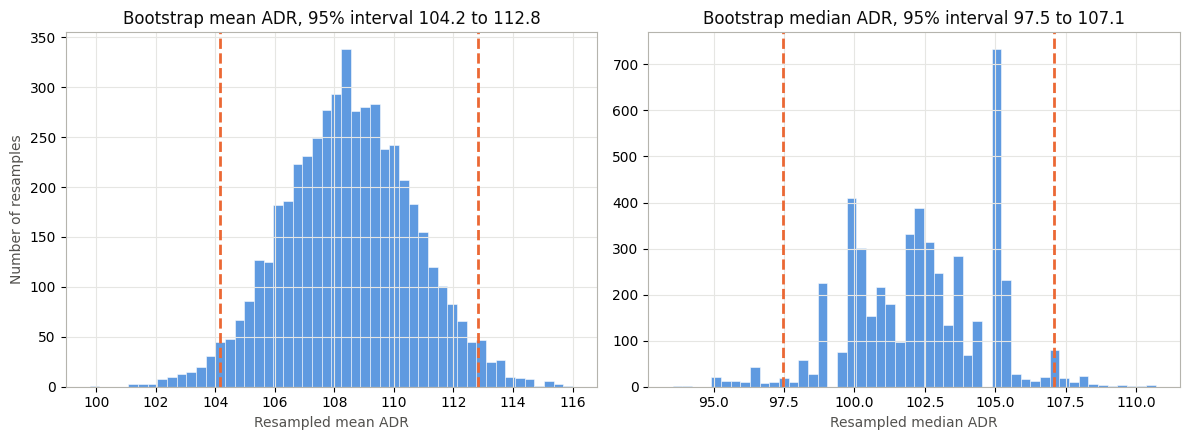

In [10]:
B = 5000
one_sample = rng.choice(population["ADR"], size=500, replace=False)

boot_idx = rng.integers(0, len(one_sample), size=(B, len(one_sample)))
boot = one_sample[boot_idx]
boot_mean, boot_median = boot.mean(axis=1), np.median(boot, axis=1)

ci_mean_boot = np.percentile(boot_mean, [2.5, 97.5])
ci_median_boot = np.percentile(boot_median, [2.5, 97.5])
se = one_sample.std(ddof=1) / np.sqrt(len(one_sample))
ci_mean_formula = one_sample.mean() + np.array([-1, 1]) * stats.t.ppf(0.975, len(one_sample) - 1) * se

print(f"One sample of 500: mean {one_sample.mean():.2f}, median {np.median(one_sample):.2f}")
print(f"95% interval for the mean, bootstrap: {ci_mean_boot.round(2)}")
print(f"95% interval for the mean, t formula: {ci_mean_formula.round(2)}")
print(f"95% interval for the median, bootstrap: {ci_median_boot.round(2)}")
print(f"True population values: mean {mu:.2f}, median {np.median(population['ADR']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, vals, ci, label in [(axes[0], boot_mean, ci_mean_boot, "mean"), (axes[1], boot_median, ci_median_boot, "median")]:
    ax.hist(vals, bins=50, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5)
    for edge in ci:
        ax.axvline(edge, color=ORANGE, lw=2, ls="--")
    ax.set_title(f"Bootstrap {label} ADR, 95% interval {ci[0]:.1f} to {ci[1]:.1f}")
    ax.set_xlabel(f"Resampled {label} ADR")
axes[0].set_ylabel("Number of resamples")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_bootstrap_adr.png", dpi=120, bbox_inches="tight")
plt.show()

### 5b. Bootstrap for the median LeadTime gap (cancelled minus not cancelled)

In [11]:
lt_c = df.loc[df["IsCanceled"] == 1, "LeadTime"].to_numpy()
lt_k = df.loc[df["IsCanceled"] == 0, "LeadTime"].to_numpy()
obs_gap = np.median(lt_c) - np.median(lt_k)

gaps = np.empty(B)
for b in range(B):
    gaps[b] = np.median(rng.choice(lt_c, len(lt_c))) - np.median(rng.choice(lt_k, len(lt_k)))
ci_gap = np.percentile(gaps, [2.5, 97.5])
print(f"Median LeadTime: cancelled {np.median(lt_c):.0f}, not cancelled {np.median(lt_k):.0f}, gap {obs_gap:.0f} days")
print(f"95% bootstrap interval for the gap: {ci_gap[0]:.0f} to {ci_gap[1]:.0f} days")

Median LeadTime: cancelled 80, not cancelled 38, gap 42 days
95% bootstrap interval for the gap: 40 to 44 days


**Result:**
- **Mean:** the bootstrap interval (104.16 to 112.82) almost matches the t formula (104.11 to 112.89). Two different methods agree.
- **Median:** the interval 97.45 to 107.10 contains the true median 98.10. Its histogram is lumpy because ADR values repeat (for example 100 and 105 appear many times), so the median can only land on a few values.
- **Median LeadTime gap:** cancelled bookings have a median lead time 42 days longer (95% interval 40 to 44). This backs up Notebook 03's mean gap of 35.62 days using a measure that long tails don't pull around.

## 6. Three ways of resampling, compared

| Method | What it does | What it answers |
|---|---|---|
| **Sampling** (Sections 2-4) | Draws new samples from the whole population | How much would a statistic vary from sample to sample? (Only possible here because we treat our data as the population) |
| **Bootstrap** (Section 5) | Resamples our one sample with replacement | Same question, when we only have one sample: gives an interval |
| **Permutation** (Notebook 03) | Shuffles the group labels | What would we see if there were no relationship? Gives a p-value |

**Why the CLT matters:** confidence intervals, z-tests, t-tests and the chi-square test all rely on sample statistics being roughly normal for large samples. The permutation test does not need it, because it builds its own reference distribution.